# Redox-Linked p*K*<sub>a</sub> Shift: APBS + PyMOL Workflow

This notebook is a tutorial walkthrough of `pka_workflow.py`, a
command-line script that estimates how the p*K*<sub>a</sub> of a titratable
group shifts when a nearby metal center changes oxidation state -- here,
the axial imidazolium N&ndash;H of a Mn(II)/Mn(III) porphyrin complex bound
to a protein.

**What the workflow does, end to end:**

1. Runs APBS (Adaptive Poisson&ndash;Boltzmann Solver) on four PQR
   structures representing the four combinations of {metal oxidation
   state} &times; {protonation state}, producing an electrostatic
   potential grid (`.dx`) and a total electrostatic energy for each.
2. Combines the four energies in an **isodesmic-style double-difference
   thermodynamic cycle** to get the electrostatic coupling free energy
   between the redox site and the protonation site, and converts that to
   a predicted pK$_\mathrm{a}$ shift.
3. Computes the electrostatic potential **difference** map between the
   two protonated states (reduced minus oxidized) with APBS's `dxmath`
   tool.
4. Writes a ready-to-run **PyMOL** script that visualizes that difference
   map as positive/negative isosurfaces on the protein structure.
5. Optionally drives PyMOL itself (headless) to render and save an image.

Every step below calls the exact same functions used by the command-line
script (`pka_workflow.py`, imported alongside this notebook) -- this
notebook just adds narration and runs them one at a time so you can
inspect the result of each stage.

**Requires:** `apbs-binary`, `pymol-open-source`, `numpy`, `pandas`
(the last only for the nicer tables in this notebook -- the CLI script
itself doesn't need it).

## Install and import the required packages

Two packages do the heavy lifting here:

- **`apbs-binary`** ships a self-contained build of APBS (and its
  companion command-line tools `dxmath`, `multivalue`, `smooth`, ...) as
  an ordinary pip-installable Python package, so you don't need a
  separate system install of APBS. It exposes each tool as a Python
  function (`apbs_binary.run_apbs(...)`, `apbs_binary.run_dxmath(...)`)
  that's really just a thin, environment-aware wrapper around
  `subprocess.run`.
- **`pymol-open-source`** is the open-source PyMOL build, importable as a
  normal Python package. Its `pymol2` submodule lets you drive a full
  PyMOL session headlessly (no GUI needed) from a script -- exactly what
  the optional visualization step at the end uses.

In [1]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("We are in Google Colab: installing apbs-binary, pymol-open-source, numpy, pandas")
    !pip install numpy pandas apbs-binary pymol-open-source-whl
else:
    print("We are not in Google Colab: all the packages are asumed to be installed in the current environment")

from importlib.metadata import version

for pkg in ["apbs-binary", "pymol-open-source-whl", "numpy", "pandas"]:
    print(f"{pkg}: {version(pkg)}")


We are not in Google Colab: all the packages are asumed to be installed in the current environment
apbs-binary: 3.4.1.1
pymol-open-source-whl: 3.2.0.1
numpy: 1.26.4
pandas: 2.3.3


In [2]:
import sys
import json
from pathlib import Path

import sys
import json
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image, Markdown, display

# pka_workflow.py must be in the same directory as this notebook
sys.path.insert(0, str(Path.cwd()))

from pka_workflow import (
    GAS_CONSTANT_KJ,
    check_pqr_coordinates_consistent,
    compute_common_box_dimensions,
    run_apbs_calculation,
    compute_pka_shift,
    compute_difference_map,
    write_pml_script,
    run_pymol_visualization,
    read_dx_values,
)

print("apbs_workflow functions imported from the external pka_workflow.py module")


apbs_workflow functions imported from the external pka_workflow.py module


## 1. Define the four charge states

The redox&ndash;protonation coupling we want is defined on **four**
electrostatic charge states of the same protein-embedded ligand geometry:

| State | Metal | N&ndash;H present? | Ligand net charge |
|---|---|---|---|
| `mn2_prot`   | Mn(II)  | yes | +1 |
| `mn2_deprot` | Mn(II)  | no  |  0 |
| `mn3_prot`   | Mn(III) | yes | +2 |
| `mn3_deprot` | Mn(III) | no  | +1 |

All four share **identical atomic coordinates and radii** for every atom
they have in common -- only the ligand's partial charges (and, for the
deprotonated states, the absence of the leaving proton) differ between
them. The protonated-state charges typically come from a DFT/MK
(Merz&ndash;Kollman) electrostatic potential fit on the bound ligand; the
deprotonated-state charges come from the same kind of fit run on the
ligand with the proton removed. Protein atoms keep one consistent force
field (e.g. AMBER ff14SB) throughout.

Edit the four paths below to point at your own PQR files, and set the
interior (solute) dielectric constant `PDIE` you want to use -- 2.0 is a
common default for a rigid, largely non-polarizable protein interior.

In [3]:
# ---- edit these for your own system -----------------------------------
MN2_PROT_PQR   = Path("apbs/complex_MNP2.pqr")
MN2_DEPROT_PQR = Path("apbs/complex_MNP2_deprot.pqr")
MN3_PROT_PQR   = Path("apbs/complex_MNP3.pqr")
MN3_DEPROT_PQR = Path("apbs/complex_MNP3_deprot.pqr")

PDIE = 4.0              # interior (solute) dielectric constant
SDIE = 78.54            # solvent dielectric constant
IONIC_STRENGTH = 0.150  # 1:1 ionic strength, mol/L
TEMP = 298.15           # temperature, K

OUTDIR = Path("notebook_output")
OUTDIR.mkdir(exist_ok=True)
# -------------------------------------------------------------------------

print(f"Interior (solute) dielectric constant: {PDIE}")
print(f"Solvent dielectric constant: {SDIE}")
print(f"Ionic strength: {IONIC_STRENGTH} mol/L")
print(f"Temperature: {TEMP} K")

print(f"Output directory: {OUTDIR}")


Interior (solute) dielectric constant: 4.0
Solvent dielectric constant: 78.54
Ionic strength: 0.15 mol/L
Temperature: 298.15 K
Output directory: notebook_output


## 2. Sanity check: do all four structures share one geometry?

The whole point of the double-difference cycle below is that everything
which *doesn't* change between states -- most of the protein, most of the
solvent -- cancels out algebraically, leaving only the electrostatic
consequence of the redox/protonation change itself. That cancellation is
only clean if all four PQR files really do share one fixed geometry.

`check_pqr_coordinates_consistent` compares the coordinates of every atom
two files have in common (matched by atom name + residue number) and
flags any disagreement. It's fine for one file to be *missing* atoms the
other has (e.g. the deprotonated states are missing the leaving proton) --
that's expected. What would be a problem is if, say, the protein backbone
had drifted between two of the files.

In [4]:
checks = [
    (MN2_PROT_PQR, MN2_DEPROT_PQR, "Mn2+ prot vs deprot"),
    (MN3_PROT_PQR, MN3_DEPROT_PQR, "Mn3+ prot vs deprot"),
    (MN2_PROT_PQR, MN3_PROT_PQR,   "Mn2+ vs Mn3+ (protonated)"),
]
for a, b, tag in checks:
    ok = check_pqr_coordinates_consistent(a, b)
    print(f"{'OK       ' if ok else 'MISMATCH '} {tag}")
    if not ok:
        print(f"  WARNING: {a.name} and {b.name} disagree on a shared atom's coordinates.")


OK        Mn2+ prot vs deprot
OK        Mn3+ prot vs deprot
OK        Mn2+ vs Mn3+ (protonated)


## 3. Choose one shared APBS grid box

APBS solves the (linearized) Poisson&ndash;Boltzmann equation on a finite
box, discretized onto a grid. For the difference map in step 6 to be a
simple point-by-point subtraction, and for the double-difference energies
in step 5 to cancel cleanly, **all four states need to be solved on
exactly the same grid** (same box size, same number of grid points, same
center).

`compute_common_box_dimensions` looks at the *union* of all four
structures' atomic extents and sizes a coarse box (with generous padding,
for a stable boundary condition) and a fine, focused box (with tighter
padding, for resolution) around it. Using the union rather than each
file's own extent independently is deliberate: if a removed proton
happened to be the outermost atom along some axis, sizing each state's
box off its own atoms alone could leave the four grids subtly
misaligned.

In [5]:
cglen, fglen = compute_common_box_dimensions(
    [MN2_PROT_PQR, MN2_DEPROT_PQR, MN3_PROT_PQR, MN3_DEPROT_PQR],
    coarse_padding=40.0,  # Angstrom added on each side, coarse grid
    fine_padding=15.0,    # Angstrom added on each side, fine (focused) grid
)
dime = (161, 161, 161)  # grid points per axis (same for coarse & fine)

print(f"coarse box (cglen): {cglen[0]:.2f} x {cglen[1]:.2f} x {cglen[2]:.2f} A")
print(f"fine box   (fglen): {fglen[0]:.2f} x {fglen[1]:.2f} x {fglen[2]:.2f} A")
print(f"grid points (dime): {dime}")


coarse box (cglen): 119.48 x 123.14 x 119.52 A
fine box   (fglen): 69.48 x 73.14 x 69.52 A
grid points (dime): (161, 161, 161)


## 4. Run APBS on each of the four states

For each state, `run_apbs_calculation`:

1. Writes an APBS input file (`mg-auto` focusing, linearized PBE,
   molecular/Connolly dielectric surface, cubic-spline charge
   discretization, 150 mM 1:1 ionic strength by default).
2. Runs APBS via `apbs_binary.run_apbs`.
3. Parses the **converged (fine-grid) total electrostatic energy** out of
   the log. (APBS's focusing scheme reports this quantity twice per run
   -- once for the coarse grid, once final for the focused fine grid --
   the fine-grid value is the one that matters.)
4. Returns the path to the written potential map (`.dx`) along with the
   energy.

This step is the expensive one -- each APBS solve typically takes tens of
seconds, so four states can take a few minutes total.

In [6]:
states = {}
for label, pqr in [
    ("mn2_prot",   MN2_PROT_PQR),
    ("mn2_deprot", MN2_DEPROT_PQR),
    ("mn3_prot",   MN3_PROT_PQR),
    ("mn3_deprot", MN3_DEPROT_PQR),
]:
    states[label] = run_apbs_calculation(
        pqr, label, PDIE, OUTDIR,
        sdie=SDIE, ionic_strength=IONIC_STRENGTH, temp=TEMP,
        dime=dime, cglen=cglen, fglen=fglen,
    )

print("\n==> Done!")

[apbs] running 'mn2_prot'  (pdie=4) ...
[apbs] 'mn2_prot': total electrostatic energy = 18170.797 kcal/mol
[apbs] running 'mn2_deprot'  (pdie=4) ...
[apbs] 'mn2_deprot': total electrostatic energy = 18147.974 kcal/mol
[apbs] running 'mn3_prot'  (pdie=4) ...
[apbs] 'mn3_prot': total electrostatic energy = 18081.792 kcal/mol
[apbs] running 'mn3_deprot'  (pdie=4) ...
[apbs] 'mn3_deprot': total electrostatic energy = 18052.739 kcal/mol

==> Done!


A quick summary table of what came out:

In [7]:
summary_df = pd.DataFrame([
    {"state": k, "PQR file": v.pqr_file.name, "Total Energy (kcal/mol)": v.total_energy_kjmol/4.184,
     "dx_file": v.dx_file.name}
    for k, v in states.items()
])

display(HTML("""
<style>
table.pka-summary th, table.pka-summary td { text-align: left; }
table.pka-summary th:nth-child(4), table.pka-summary td:nth-child(4) { text-align: right; }
</style>
<h3>Summary of APBS calculations</h3>
""" + summary_df.to_html(
    classes="pka-summary",
    formatters={"Total Energy (kcal/mol)": lambda x: f'<b style="color:red">{x:,.3f}</b>'},
    escape=False,
)))


,state,PQR file,Total Energy (kcal/mol),dx_file
0,mn2_prot,complex_MNP2.pqr,"18,170.797",pot_mn2_prot.dx
1,mn2_deprot,complex_MNP2_deprot.pqr,"18,147.974",pot_mn2_deprot.dx
2,mn3_prot,complex_MNP3.pqr,"18,081.792",pot_mn3_prot.dx
3,mn3_deprot,complex_MNP3_deprot.pqr,"18,052.739",pot_mn3_deprot.dx


## 5. The isodesmic double-difference thermodynamic cycle

The four states above form a thermodynamic square:

<div style="text-align: center;">
<pre style="display: inline-block; text-align: left; background: transparent; border: none; padding: 0; margin: 0 auto;">
   Mn(II)P-BIPH ---- oxidation ---->  Mn(III)P-BIPH
             |                                   | 
     dG_deprot(Mn2+)                     dG_deprot(Mn3+)
             |                                   |
             v                                   v
   Mn(II)P-BIP  ---- oxidation ---->  Mn(III)P-BIP
</pre>
</div>

Define the deprotonation free energy at each fixed oxidation state as

$$\Delta G_{\mathrm{deprot}}(\mathrm{Mn}^{n+}) = G(\mathrm{Mn}^{n+}, \text{deprot}) - G(\mathrm{Mn}^{n+}, \text{prot})$$

The redox-linked **coupling free energy** is the double difference

$$\Delta\Delta G = \Delta G_{\mathrm{deprot}}(\mathrm{Mn}^{3+}) - \Delta G_{\mathrm{deprot}}(\mathrm{Mn}^{2+})$$

Because this is itself a difference of differences, everything that does
**not** depend on *both* the redox state and the protonation state cancels
out identically -- in particular, the intrinsic (bulk-solvent,
model-compound) deprotonation free energy of the imidazolium group and
the proton's own reference chemical potential. That's what makes it
possible to get a physically meaningful **p*K*<sub>a</sub> shift** directly
from four protein-embedded continuum-electrostatics calculations, with no
separate small-molecule-in-solvent reference calculation needed -- as long
as it's the *shift*, not the absolute p*K*<sub>a</sub>, that you're after.
This is the same style of error-cancelling double-difference used in
isodesmic reaction schemes, and it follows the classic
Bashford & Karplus (*Biochemistry* **29**, 10219-10225, 1990) formalism for
electrostatic p*K*<sub>a</sub>/redox coupling in proteins.

The p*K*<sub>a</sub> shift itself follows from

$$\Delta\mathrm{p}K_\mathrm{a} = \frac{\Delta\Delta G}{RT\ln 10}$$


In [8]:
pka = compute_pka_shift(
    states["mn2_prot"].total_energy_kjmol,
    states["mn2_deprot"].total_energy_kjmol,
    states["mn3_prot"].total_energy_kjmol,
    states["mn3_deprot"].total_energy_kjmol,
    temp=TEMP,
)

display(Markdown(rf"""
| Quantity | Value | Unit |
|:---|---:|:---|
| $\Delta G_{{\mathrm{{deprot}}}}(\mathrm{{Mn}}^{{2+}})$ | ${pka.dG_deprot_reduced/4.184:.3f}$ | kcal/mol |
| $\Delta G_{{\mathrm{{deprot}}}}(\mathrm{{Mn}}^{{3+}})$ | ${pka.dG_deprot_oxidized/4.184:.3f}$ | kcal/mol |
| $\Delta\Delta G$ | ${pka.ddG_coupling/4.184:.3f}$ | kcal/mol |
| $RT \ln 10$ $(T = {TEMP}\ \mathrm{{K}})$ | ${pka.rt_ln10/4.184:.4f}$ | kcal/mol |
| $\Delta\mathrm{{p}}K_{{\mathrm{{a}}}}$ ($\mathrm{{Mn}}^{{3+}}$/$\mathrm{{Mn}}^{{2+}}$) | ${pka.dpka:+.2f}$ | |
"""))



| Quantity | Value | Unit |
|:---|---:|:---|
| $\Delta G_{\mathrm{deprot}}(\mathrm{Mn}^{2+})$ | $-22.823$ | kcal/mol |
| $\Delta G_{\mathrm{deprot}}(\mathrm{Mn}^{3+})$ | $-29.053$ | kcal/mol |
| $\Delta\Delta G$ | $-6.230$ | kcal/mol |
| $RT \ln 10$ $(T = 298.15\ \mathrm{K})$ | $1.3642$ | kcal/mol |
| $\Delta\mathrm{p}K_{\mathrm{a}}$ ($\mathrm{Mn}^{3+}$/$\mathrm{Mn}^{2+}$) | $-4.57$ | |


A negative shift here means oxidizing Mn(II) &rarr; Mn(III) makes the imidazolium N&ndash;H group in BIP **more acidic** (lower p*K*<sub>a</sub>) -- physically sensible, since the extra positive charge on the oxidized metal destabilizes the still-protonated (net more positive) form of the ligand more than the deprotonated (neutral) form.

## 6. Electrostatic Potential Difference map

To *see* where in space the Mn(II) and Mn(III) protonated states'
electrostatic potentials actually differ, subtract their two `.dx` maps
point-by-point with APBS's `dxmath` tool (this only works cleanly because
both maps were solved on the identical grid set up in step 3).

In [9]:
diff_dx = compute_difference_map(
    states["mn2_prot"].dx_file,
    states["mn3_prot"].dx_file,
    "pot_diff_mn2_minus_mn3.dx",
    OUTDIR,
)
print(f"difference map written to: {diff_dx}")

vals = read_dx_values(diff_dx)
print(f"value range: {vals.min():.2f} to {vals.max():.2f} kT/e   (std dev: {vals.std():.3f})")


[dxmath] computing pot_diff_mn2_minus_mn3.dx = pot_mn2_prot.dx - pot_mn3_prot.dx
difference map written to: notebook_output/pot_diff_mn2_minus_mn3.dx
value range: -88.85 to 42.30 kT/e   (std dev: 0.873)


## 7. Generate a PyMOL visualization script

Raw (unsmoothed) APBS potential/difference maps carry large, sharp values
right at each atom's own position -- a numerical artifact of representing
a point charge on a finite grid (its "self-energy"), not a meaningful
feature of the field. A *fixed* isosurface level that looks fine for one
`pdie`/grid combination can therefore end up either showing nothing, or
engulfing the entire structure in a solid blob, at another.

`suggest_isovalue` sidesteps this by picking a level from the map's own
statistics -- a small multiple of its standard deviation -- so the
isosurface stays informative (structured signal, not background noise or
a single solid blob) across different runs.

In [10]:
minvalue = -2.0
maxvalue = 2.0
pml_file = write_pml_script(
    states["mn2_prot"].pqr_file,
    diff_dx,
    OUTDIR / "diff_map_viz.pml",
    minvalue=minvalue,
    maxvalue=maxvalue,
)
print(f"PyMOL script written to: {pml_file}")
print(f"Run the following command to view the difference map in PyMOL: pymol {pml_file}")

[pymol] wrote visualization script: notebook_output/diff_map_viz.pml
PyMOL script written to: notebook_output/diff_map_viz.pml
Run the following command to view the difference map in PyMOL: pymol notebook_output/diff_map_viz.pml


This `.pml` file is entirely standalone -- from a terminal you can
run it directly against any PyMOL install with:

```bash
pymol diff_map_viz.pml
```

which opens an interactive PyMOL session with the difference map already
loaded and rendered. The next (optional) step does the same thing, but
headlessly, from Python.

## 8. (Optional) Render with headless PyMOL

`pymol2.PyMOL()` starts a full PyMOL session with no GUI window, so it can
run inside a script or notebook. `run_pymol_visualization` executes the
`.pml` script from step 7 in that session, then ray-traces and saves a
PNG. This step is the second-most expensive in the notebook (ray-tracing
a molecular surface at reasonable resolution takes a little while) --
skip it if you only need the raw `.dx`/`.pml` files.

[pymol] launching headless PyMOL session ...
[pymol] saved image: notebook_output/diff_map_view.png


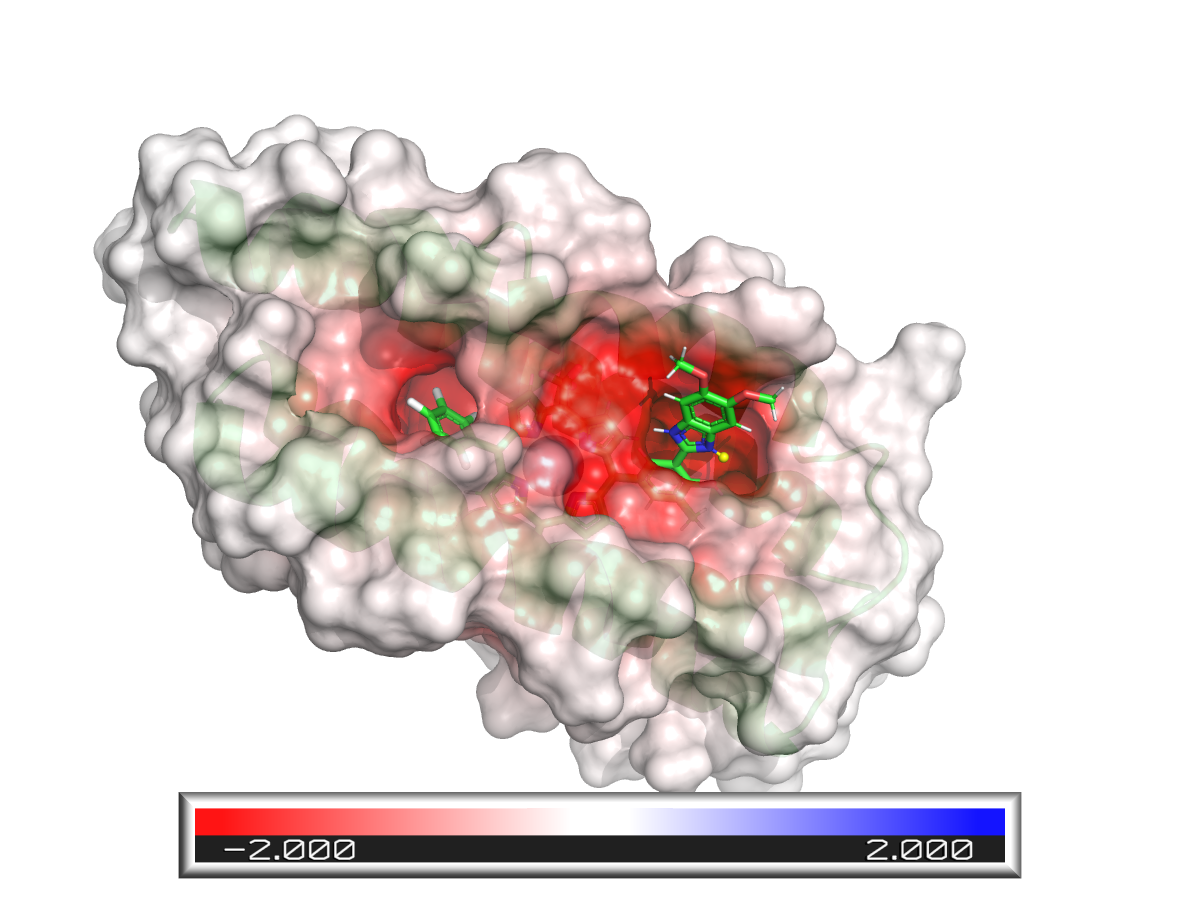

In [11]:
png_out = OUTDIR / "diff_map_view.png"
run_pymol_visualization(pml_file, png_out=png_out, width=1200, height=900, dpi=300)
display(Image(filename=str(png_out)))

## Summary

- **Predicted pK$_\mathrm{a}$ shift** upon Mn(II) &rarr; Mn(III) oxidation: see the printed value in step 5.
- All raw outputs (`.in`, `.log`, `.dx` potential maps, the difference map, the `.pml` script, and the rendered PNG) are in the `notebook_output/` directory.

To sweep other parameters (a different `pdie`, different PQR files entirely), you don't need to re-run this notebook -- the command-line version handles that directly, e.g.:

```bash
python pka_workflow.py \\
    --mn2-prot complex_MNP2.pqr --mn2-deprot complex_MNP2_deprot.pqr \\
    --mn3-prot complex_MNP3.pqr --mn3-deprot complex_MNP3_deprot.pqr \\
    --pdie 4.0 --outdir results_pdie4
```